# Forecasting the Budget Seasons · a Healthcare Distributor

The companion Power BI report (*Big Tickets, Budget Seasons*) covers three years of invoice lines from an Indonesian distributor of medical and aesthetic devices
(Jan 2019 – Mar 2022, IDR). It shows that **a few large public-hospital orders make up most of the revenue**, and that they arrive in the **budget season** at the end of the year.
A dashboard shows what happened. This notebook asks what the business can plan for:

1. **When do customers buy?** The budget calendar by customer segment (public hospitals, private hospitals, clinics, companies, individual doctors).
2. **How far ahead can revenue be forecast?** Six forecasting methods (naive, seasonal naive, 12-month average, seasonal profile, ETS, SARIMA) and LightGBM, compared in a rolling-origin backtest.
3. **What range should the plan use?** A two-part simulation: a steady run-rate plus randomly timed big tickets, giving P10 / P50 / P90 for the next twelve months.
4. **Which customers are going quiet?** A purchase-probability model tested on months it never saw, and a short list of regular customers who are overdue.

Customers and sales reps are anonymised in every output (`Public 001`, `Doctor 014`, `Rep 03`). The raw file is not included.

### Key Findings
* **Two businesses in one.** Public hospitals and health offices are **7% of customers but 57% of revenue**, almost all of it in big tickets (Rp500M+), and they buy on a **budget calendar**: 0% in Jan–Feb, 59% in Aug, Nov and Dec. Clinics and doctors place many small, steady orders.
* **Monthly revenue cannot be forecast well from history alone.** Over 13 forecast origins, no method beats about **60% error (WAPE) on 3-month totals**, and every method under-forecast the 2021 budget surge. LightGBM does no better than a 12-month average: 39 months is too little history for machine learning.
* **The run-rate can be forecast.** Without big tickets, the error falls to **33–34% on 3-month totals**, and the simple 12-month average is almost unbiased (−2%).
* **A range is more honest than a number.** A run-rate + random big-ticket simulation gives **Rp23.4B (P50) for Apr 2022 – Mar 2023**, with an 80% range of Rp12.1B – Rp44.0B. Even this wide range held only 54% of past 3-month windows, because tenders come in bursts. Timing them needs a sales pipeline, not more modelling.
* **Customers going quiet can be spotted early.** A simple logistic model ranks who orders in the next six months with **ROC AUC 0.85** on unseen months (the "days since last order" rule: 0.80). Regular customers more than twice past their usual gap ordered again only **19%** of the time, against 56% for those on schedule. **59 such customers** are overdue today.

In [1]:
# ---- where things live -------------------------------------------------------------------------
import os, sys
from pathlib import Path
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))   # silences a harmless joblib warning on Windows

MAIN_FOLDERS = [Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\Healthcare Distributor")]
DATA_OVERRIDE = r""   # optional: full path of the raw invoice .xlsx

CODE_OVERRIDE = r""   # optional: the folder that contains hdtools.py

def find_module(name):
    """Find hdtools.py: next to the notebook, in a parent folder, or under the usual Windows folders.
    A renamed download such as 'hdtools (1).py' also works."""
    if CODE_OVERRIDE:
        hits = sorted(Path(CODE_OVERRIDE).glob(name + "*.py"))
        if hits:
            return hits[0]
    for p in [Path.cwd(), *Path.cwd().parents]:
        hits = sorted(p.glob(name + "*.py"))
        if hits:
            return hits[0]
    home = Path.home()
    for root in [*MAIN_FOLDERS, home / "OneDrive" / "Documents", home / "Documents", home / "Downloads", home / "Desktop", home / "OneDrive"]:
        if root.exists():
            try:
                hits = [h for h in root.rglob(name + "*.py") if ".ipynb_checkpoints" not in h.parts]
            except OSError:
                continue
            if hits:
                return sorted(hits, key=lambda f: (len(f.parts), f.name))[0]
    return None

MODULE_FILE = find_module("hdtools")
if MODULE_FILE is None:
    raise FileNotFoundError("hdtools.py not found. Put it in the same folder as this notebook, or paste that folder into CODE_OVERRIDE.")
CODE = MODULE_FILE.parent
os.chdir(CODE)
sys.path.insert(0, str(CODE))
import importlib.util
_spec = importlib.util.spec_from_file_location("hdtools", MODULE_FILE)
hd = importlib.util.module_from_spec(_spec)
sys.modules["hdtools"] = hd
_spec.loader.exec_module(hd)

DATA = Path(DATA_OVERRIDE) if DATA_OVERRIDE else hd.find_workbook(
    [CODE / "data", CODE, CODE.parent / "data", CODE.parent, *MAIN_FOLDERS, *[m / "data" for m in MAIN_FOLDERS]])
if DATA is None or not DATA.exists():
    raise FileNotFoundError("Invoice workbook not found. Put the .xlsx in the data folder, or paste its full path into DATA_OVERRIDE.")

IMAGES = next((p for p in [CODE / "images", CODE.parent / "images"] if p.exists()), CODE / "images")
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

print("Code:", CODE.name, "| Data:", DATA.name, "| Images:", IMAGES.name)

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import lightgbm as lgb
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from hdtools import GREEN, GREEN_D, GREEN_L, AMBER, RED, PLUM, SLATE, INK, MUTED, LINE, SEGMENT_COLORS, GROUP_COLORS

hd.style_charts()

Code: Documents | Data: Sales Invoice List Detail (2022-03-31).xlsx | Images: images


## 1 · Load and Reconcile With the Dashboard

Same cleaning rules as the Power BI model: one Durable/Disposable label per item (its majority label), **Pandemic response** = the COVID test-kit and PPE brands,
an order = one customer on one invoice date, and a **big ticket** = an order of Rp500M or more.
Customers are put into five segments from the institution name (for example `RSUD` / `Dinas Kesehatan` → public, `Klinik` / `Clinic` → clinic). Individual doctors are the "Personal" class.

In [2]:
d = hd.load(DATA, anonymise=True)
orders = d.groupby("order_key").agg(date=("Invoice Date", "first"), customer=("Customer ID", "first"), segment=("segment", "first"),
                                    amount=("Invoice Amount", "sum")).reset_index()
orders["big_ticket"] = orders.amount >= 500_000_000

check = pd.DataFrame({
    "revenue (Rp B)": d.groupby(d["Invoice Date"].dt.year)["Invoice Amount"].sum() / 1e9,
    "orders": orders.groupby(orders.date.dt.year).size(),
    "customers": d.groupby(d["Invoice Date"].dt.year)["Customer ID"].nunique()})
check.index.name = "year"
print(f"{len(d):,} invoice lines · {d['Customer ID'].nunique()} customers · {orders.shape[0]:,} orders · "
      f"total {hd.rp(d['Invoice Amount'].sum())} · {d['Invoice Date'].min():%b %Y} – {d['Invoice Date'].max():%b %Y}")
check.style.format({"revenue (Rp B)": "{:.1f}", "orders": "{:,}", "customers": "{:,}"})

6,381 invoice lines · 934 customers · 3,447 orders · total Rp74.3B · Jan 2019 – Mar 2022


,revenue (Rp B),orders,customers
year,,,
2019,16.9,"1,153",446
2020,25.8,"1,240",454
2021,26.5,914,348
2022,5.1,140,78


## 2 · Who Buys and When

### 2.1 Five Segments, Very Different Behaviour

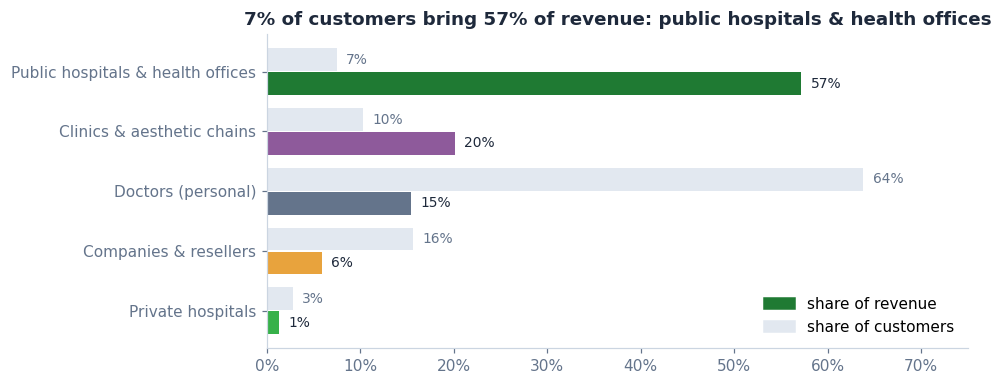

,customers,orders,revenue share,customer share,orders per customer,avg order (Rp M),big-ticket share,Q4 share (core),consumables share
segment,,,,,,,,,
Public hospitals & health offices,70,129,57%,7%,1.8,329,90%,47%,29%
Clinics & aesthetic chains,96,874,20%,10%,9.1,17,18%,31%,23%
Doctors (personal),596,"2,040",15%,64%,3.4,6,21%,35%,28%
Companies & resellers,146,338,6%,16%,2.3,13,0%,38%,5%
Private hospitals,26,66,1%,3%,2.5,15,0%,11%,12%


In [3]:
seg = d.groupby("segment").agg(customers=("Customer ID", "nunique"), revenue=("Invoice Amount", "sum"))
seg["orders"] = orders.groupby("segment").size()
seg["revenue share"] = seg.revenue / seg.revenue.sum()
seg["customer share"] = seg.customers / seg.customers.sum()
seg["orders per customer"] = seg.orders / seg.customers
seg["avg order (Rp M)"] = seg.revenue / seg.orders / 1e6
seg["big-ticket share"] = orders[orders.big_ticket].groupby("segment").amount.sum().reindex(seg.index).fillna(0) / seg.revenue
core = d[d.product_group != "Pandemic response"]
full = core[core["Invoice Date"].dt.year <= 2021]
seg["Q4 share (core)"] = full[full["Invoice Date"].dt.month >= 10].groupby("segment")["Invoice Amount"].sum() / full.groupby("segment")["Invoice Amount"].sum()
seg["consumables share"] = d[d.product_group == "Consumables"].groupby("segment")["Invoice Amount"].sum().reindex(seg.index).fillna(0) / seg.revenue
seg = seg.sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(seg))
ax.barh(y + 0.2, seg["revenue share"], height=0.38, color=[SEGMENT_COLORS[s] for s in seg.index], label="share of revenue")
ax.barh(y - 0.2, seg["customer share"], height=0.38, color=LINE, label="share of customers")
for i, (r, c) in enumerate(zip(seg["revenue share"], seg["customer share"])):
    ax.text(r + 0.01, i + 0.2, f"{r:.0%}", va="center", fontsize=9, color=INK)
    ax.text(c + 0.01, i - 0.2, f"{c:.0%}", va="center", fontsize=9, color=MUTED)
ax.set_yticks(y); ax.set_yticklabels(seg.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_xlim(0, 0.75)
ax.legend(handles=[Patch(color=GREEN_D, label="share of revenue"), Patch(color=LINE, label="share of customers")], frameon=False, loc="lower right")
top = seg.index[0]
ax.set_title(f"{seg.loc[top, 'customer share']:.0%} of customers bring {seg.loc[top, 'revenue share']:.0%} of revenue: {top.lower()}")
plt.tight_layout(); save(fig, "segments"); plt.show()

seg.drop(columns=["revenue"]).style.format({"customers": "{:,}", "orders": "{:,}", "revenue share": "{:.0%}", "customer share": "{:.0%}",
    "orders per customer": "{:.1f}", "avg order (Rp M)": "{:,.0f}", "big-ticket share": "{:.0%}", "Q4 share (core)": "{:.0%}", "consumables share": "{:.0%}"})

**Reading the Table**
* **Public hospitals and health offices**: 70 customers, 1.8 orders each, an average order of **Rp329M**, and **90%** of their revenue from big tickets. Nearly half of their core revenue (47%) lands in Q4.
* **Clinics and aesthetic chains** are the most loyal: **9.1 orders per customer** at about Rp17M each. That is a steady consumables-and-devices business worth 20% of revenue.
* **Individual doctors** are 64% of customers but 15% of revenue, with Rp6M orders.
* Companies/resellers and private hospitals are small. Private hospitals' 54% September share is one large order, not a pattern.

### 2.2 The Budget Calendar

Share of each segment's yearly revenue that lands in each calendar month (2019–2021, Pandemic response excluded so the COVID test-kit wave does not distort the pattern).

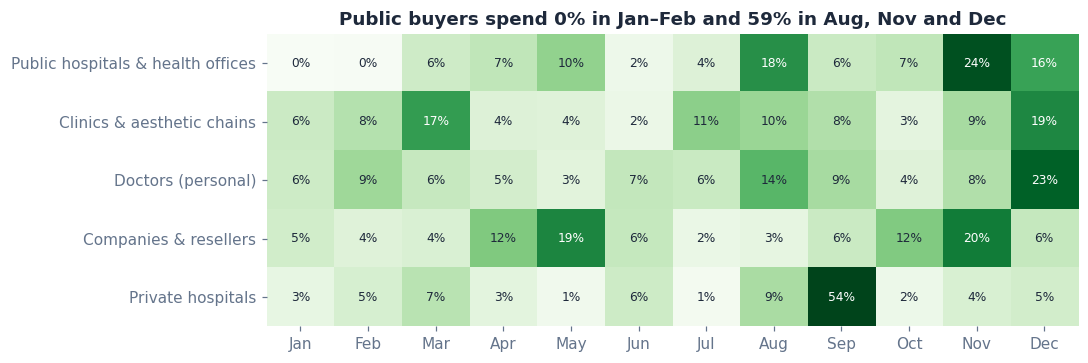

In [4]:
cal = full.pivot_table(index=full["Invoice Date"].dt.month, columns="segment", values="Invoice Amount", aggfunc="sum").reindex(range(1, 13)).fillna(0)
cal = cal / cal.sum()
order = ["Public hospitals & health offices", "Clinics & aesthetic chains", "Doctors (personal)", "Companies & resellers", "Private hospitals"]
cal = cal[order]

fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(cal.T.values, aspect="auto", cmap="Greens", vmin=0, vmax=0.25)
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
for i in range(len(order)):
    for j in range(12):
        v = cal.T.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.15 else INK)
ax.spines[:].set_visible(False)
pub = cal["Public hospitals & health offices"]
ax.set_title(f"Public buyers spend {pub[[1, 2]].sum():.0%} in Jan–Feb and {pub[[8, 11, 12]].sum():.0%} in Aug, Nov and Dec")
plt.tight_layout(); save(fig, "budget calendar"); plt.show()

**Reading the Calendar**
* **Public buyers do not buy in January and February.** This fits how regional budgets usually run: new-year budgets take time to become spendable, mid-year revisions free money around **August**, and unspent budget is used up in **November–December**.
* **Clinics and doctors peak in December and March**, but their spending is spread far more evenly.
* For planning, the year has three seasons: a **quiet Q1** carried by clinics and doctors, an **August spike**, and a **November–December peak** that can bring a quarter of a year's public revenue in one month. Stock, cash and sales effort should follow that calendar.

### 2.3 Run-Rate and Big Tickets

Every month's revenue split into **run-rate** (orders under Rp500M), **big tickets** (≥ Rp500M) and the one-off **Pandemic response** wave.

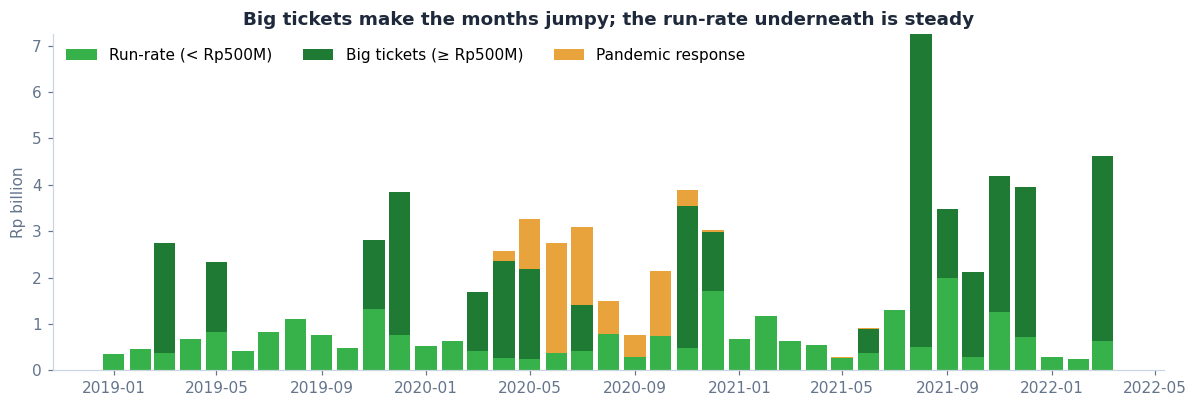

Big tickets: 38 orders = 60% of core revenue (89% from public buyers).
Month-to-month variability (coefficient of variation): run-rate 0.61, big tickets 1.48


In [5]:
idx = hd.month_index(d.month.min(), d.month.max())
split = pd.DataFrame({
    "Run-rate (< Rp500M)": core[~core.big_ticket].groupby("month")["Invoice Amount"].sum(),
    "Big tickets (≥ Rp500M)": core[core.big_ticket].groupby("month")["Invoice Amount"].sum(),
    "Pandemic response": d[d.product_group == "Pandemic response"].groupby("month")["Invoice Amount"].sum()}).reindex(idx).fillna(0) / 1e9

fig, ax = plt.subplots(figsize=(11, 3.8))
bottom = np.zeros(len(split))
for col, c in zip(split.columns, [GREEN, GREEN_D, AMBER]):
    ax.bar(split.index, split[col], width=25, bottom=bottom, color=c, label=col)
    bottom += split[col].values
ax.set_ylabel("Rp billion"); ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Big tickets make the months jumpy; the run-rate underneath is steady")
plt.tight_layout(); save(fig, "run rate and big tickets"); plt.show()

big = orders[orders.big_ticket & orders.order_key.isin(core.order_key)]
cv = split.iloc[:, :2].std() / split.iloc[:, :2].mean()
print(f"Big tickets: {len(big)} orders = {big.amount.sum() / core['Invoice Amount'].sum():.0%} of core revenue "
      f"({(big.segment == 'Public hospitals & health offices').mean():.0%} from public buyers).")
print(f"Month-to-month variability (coefficient of variation): run-rate {cv.iloc[0]:.2f}, big tickets {cv.iloc[1]:.2f}")

**Reading the Split**
* **38 big-ticket orders are 60% of core revenue**, and 89% of them are public buyers.
* The run-rate still varies (coefficient of variation 0.61), but big tickets vary **2.4× as much** (1.48). August 2021 alone brought Rp7.3B, mostly from big tickets.
* Any single-number monthly forecast mixes a predictable part with an unpredictable one. The next section measures how much that costs.

## 3 · How Well Can Revenue be Forecast?

**Rolling-origin backtest.** At the end of every month from Dec 2020 to Dec 2021, each method sees only the history up to that month and forecasts the next three months.
That gives 13 forecast origins and up to 39 forecasted months, all outside the training data. The Pandemic response wave is excluded: it will not repeat.

* **Naive**: next month = last month.
* **Seasonal naive**: same month last year.
* **12-month average**: the mean of the last 12 months.
* **Seasonal profile**: the last 12 months' total × each calendar month's historical share (the "budget calendar").
* **ETS**: Holt-Winters with additive yearly seasonality (on log revenue).
* **SARIMA**: seasonal AR(12) with a constant (on log revenue).
* **LightGBM**: a single model across the 10 product-group × segment series (lags, rolling mean, calendar month), one model per horizon.

Scored with **WAPE** (total absolute error ÷ total actual; 0% is perfect) on single months and on 3-month totals.

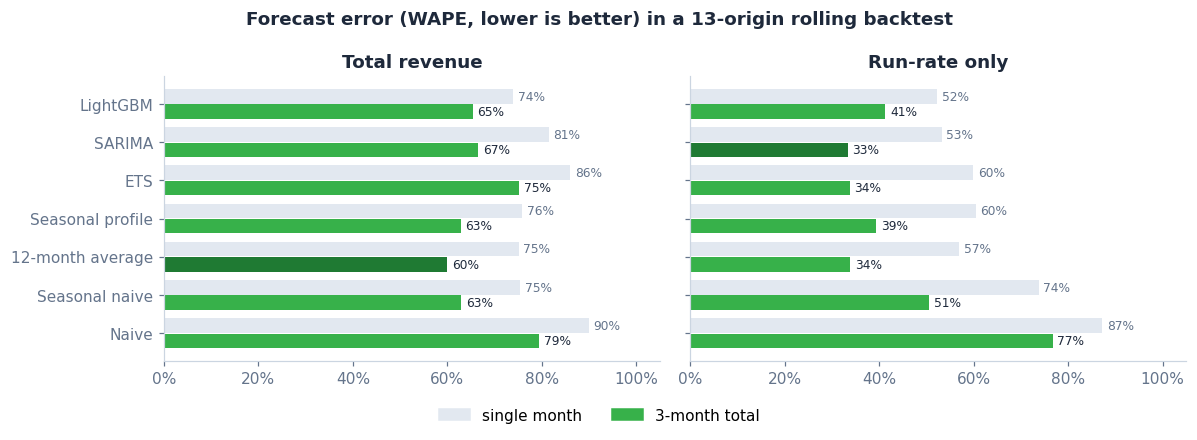

series,method,WAPE monthly,WAPE 3-month total,bias
Total revenue,Naive,90%,79%,+7%
Total revenue,Seasonal naive,75%,63%,-33%
Total revenue,12-month average,75%,60%,-25%
Total revenue,Seasonal profile,76%,63%,-38%
Total revenue,ETS,86%,75%,-17%
Total revenue,SARIMA,81%,67%,-41%
Total revenue,LightGBM,74%,65%,-39%
Run-rate only,Naive,87%,77%,+20%
Run-rate only,Seasonal naive,74%,51%,-17%
Run-rate only,12-month average,57%,34%,-2%


In [6]:
def series(df):
    return df.groupby("month")["Invoice Amount"].sum().reindex(idx).fillna(0) / 1e9

y_all, y_run = series(core), series(core[~core.big_ticket])
H, ORIGINS = 3, pd.date_range("2020-12-01", "2021-12-01", freq="MS")

def point_forecast(train, h, how):
    fut = pd.date_range(train.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
    if how == "Naive":
        return pd.Series(train.iloc[-1], fut)
    if how == "Seasonal naive":
        return pd.Series([train[f - pd.DateOffset(years=1)] for f in fut], fut)
    if how == "12-month average":
        return pd.Series(train.iloc[-12:].mean(), fut)
    if how == "Seasonal profile":
        share = train.groupby(train.index.month).sum() / train.sum()
        return pd.Series([train.iloc[-12:].sum() * share[f.month] for f in fut], fut)
    if how == "ETS":
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = ExponentialSmoothing(np.log1p(train.values), trend=None, seasonal="add", seasonal_periods=12).fit()
        return pd.Series(np.expm1(m.forecast(h)).clip(0), fut)
    if how == "SARIMA":
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = SARIMAX(np.log1p(train.values), order=(0, 0, 0), seasonal_order=(1, 0, 0, 12), trend="c").fit(disp=False)
        return pd.Series(np.expm1(m.forecast(h)).clip(0), fut)

def lgbm_forecasts(df, total):
    # one global model over product group x segment series, one model per horizon (direct strategy)
    p = df.pivot_table(index="month", columns=["product_group", "segment"], values="Invoice Amount", aggfunc="sum").reindex(idx).fillna(0) / 1e9
    long = p.stack([0, 1]).rename("y").reset_index()
    long.columns = ["month", "group", "segment", "y"]
    long = long.sort_values(["group", "segment", "month"]).reset_index(drop=True)
    g = long.groupby(["group", "segment"]).y
    for k in range(1, 13):
        long[f"lag{k}"] = g.shift(k)
    long["calendar_month"] = long.month.dt.month
    long["group"] = long.group.astype("category"); long["segment"] = long.segment.astype("category")
    out = {}
    for h in range(1, H + 1):   # build the features once per horizon, then refit for each origin
        X = long.copy()
        X["recent_mean"] = X[[f"lag{k}" for k in range(h, h + 3)]].mean(axis=1)
        feats = [f"lag{k}" for k in (h, h + 1, h + 2, 12) if k <= 12] + ["recent_mean", "calendar_month", "group", "segment"]
        for o in ORIGINS:
            tr = X[(X.month <= o) & X[f"lag{h}"].notna()]
            # n_jobs=1: tiny data, so one thread is fastest, and LightGBM skips the slow CPU-core check on Windows
            mdl = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=7, min_child_samples=5, n_jobs=1, verbose=-1)
            mdl.fit(tr[feats], np.log1p(tr.y))
            t = o + pd.DateOffset(months=h)
            te = X[X.month == t]
            if len(te):
                out[(o, t)] = np.expm1(mdl.predict(te[feats])).clip(0).sum()
    return out

METHODS = ["Naive", "Seasonal naive", "12-month average", "Seasonal profile", "ETS", "SARIMA", "LightGBM"]
rows = []
for name, y, src in [("Total revenue", y_all, core), ("Run-rate only", y_run, core[~core.big_ticket])]:
    lg = lgbm_forecasts(src, y)
    for how in METHODS:
        a, f, A, F = [], [], [], []
        for o in ORIGINS:
            if how == "LightGBM":
                fc = pd.Series({t: v for (oo, t), v in lg.items() if oo == o})
            else:
                fc = point_forecast(y[:o], H, how)
            act = y.reindex(fc.index).dropna()
            a += list(act); f += list(fc[act.index])
            if len(act) == H:
                A.append(act.sum()); F.append(fc[act.index].sum())
        rows.append((name, how, hd.wape(a, f), hd.wape(A, F), np.sum(f) / np.sum(a) - 1))
bt = pd.DataFrame(rows, columns=["series", "method", "WAPE monthly", "WAPE 3-month total", "bias"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, g) in zip(axes, bt.groupby("series", sort=False)):
    g = g.set_index("method").reindex(METHODS)
    best = g["WAPE 3-month total"].idxmin()
    yy = np.arange(len(g))
    ax.barh(yy + 0.2, g["WAPE monthly"], height=0.38, color=LINE)
    ax.barh(yy - 0.2, g["WAPE 3-month total"], height=0.38, color=[GREEN_D if m == best else GREEN for m in g.index])
    for i, (m1, m3) in enumerate(zip(g["WAPE monthly"], g["WAPE 3-month total"])):
        ax.text(m1 + 0.01, i + 0.2, f"{m1:.0%}", va="center", fontsize=8, color=MUTED)
        ax.text(m3 + 0.01, i - 0.2, f"{m3:.0%}", va="center", fontsize=8, color=INK)
    ax.set_yticks(yy); ax.set_yticklabels(g.index); ax.invert_yaxis(); ax.set_xlim(0, 1.05)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(name)
fig.legend(handles=[Patch(color=LINE, label="single month"), Patch(color=GREEN, label="3-month total")], frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Forecast error (WAPE, lower is better) in a 13-origin rolling backtest", fontweight="bold", color=INK)
plt.tight_layout(rect=(0, 0.04, 1, 1)); save(fig, "model backtest"); plt.show()

bt.style.hide(axis="index").format({"WAPE monthly": "{:.0%}", "WAPE 3-month total": "{:.0%}", "bias": "{:+.0%}"})

**Reading the Backtest**
* **Total revenue:** single-month errors are 74–90%, and the best 3-month error is **60%**, from the plain 12-month average. All methods were **biased low** (−17% to −41%): none could foresee the mid-2021 burst of tenders after the 2020 COVID budget reallocation.
* **Run-rate only:** errors drop to **33–34%** on 3-month totals for ETS, SARIMA and the 12-month average. The 12-month average is the least biased (−2%) and needs no tuning.
* **LightGBM is not better** (41% on run-rate 3-month totals). With 39 months and ten small series, a tree model has too little to learn from, and the extra complexity buys nothing. That is a useful result in itself: **use the simplest model that matches the best**, and put the effort into the big tickets.

## 4 · A Plan With a Range: Run-Rate + Big Tickets

Since big tickets cannot be timed from history, the forecast treats them as **random events** and gives a range instead of a single number:

* **Run-rate**: the 12-month average, with monthly noise and a level drift taken from the history (log-normal).
* **Big tickets**: the number per month is Poisson. The yearly count is the last 12 months' count, spread over the calendar by the historical budget pattern.
  A shared random multiplier (Gamma, fitted to quarter-to-quarter swings) lets them come in bursts, as they do in budget years. Each ticket's size is drawn from past big tickets.
* 10,000 simulated years → **P10 / P50 / P90**.

First the same rolling backtest, to see whether the range can be trusted.

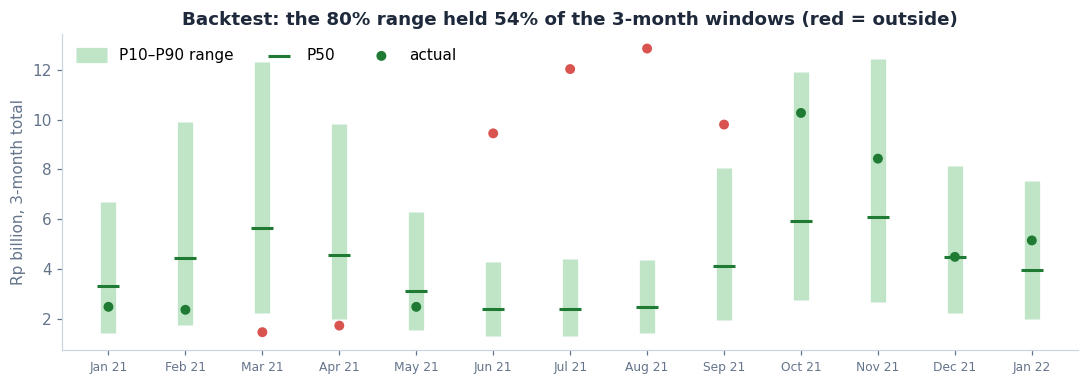

P50 WAPE on 3-month totals: 62% · windows above P90: 4 · below P10: 2


In [7]:
big_core = big[["order_key", "date", "amount"]].assign(month=lambda x: x.date.dt.to_period("M").dt.to_timestamp())

def simulate(origin, h=3, n=10000, seed=7):
    rng = np.random.default_rng(seed)
    tr = y_run[:origin]
    fut = pd.date_range(origin + pd.offsets.MonthBegin(), periods=h, freq="MS")
    base = tr.iloc[-12:].mean()
    ratio = np.log((tr / tr.rolling(12).mean().shift(1)).dropna().clip(lower=0.05))
    t12 = tr.rolling(12).sum()
    growth = np.log(t12 / t12.shift(12)).dropna()
    sd_level = growth.std() if len(growth) > 2 else 0.3
    drift = rng.normal(0, sd_level, (n, 1)) * np.sqrt(np.arange(1, h + 1) / 12)
    run = base * np.exp(rng.normal(ratio.mean(), ratio.std(), (n, h)) + drift)

    past = big_core[big_core.month <= origin]
    shape = past.groupby(past.month.dt.month).size().reindex(range(1, 13)).fillna(0) + 1.0
    shape = shape / shape.sum()
    per_year = (past.month > origin - pd.DateOffset(months=12)).sum()
    q = past.groupby(past.month.dt.to_period("Q")).size().reindex(pd.period_range(past.month.min(), origin, freq="Q")).fillna(0)
    k = q.mean() ** 2 / (q.var() - q.mean()) if q.var() > q.mean() else 50.0
    burst = rng.gamma(k, 1 / k, (n, 1))
    counts = rng.poisson(np.array([per_year * shape[f.month] for f in fut])[None, :] * burst)
    sizes = past.amount.values / 1e9
    draws = rng.choice(sizes, counts.sum())
    tickets = np.zeros_like(run)
    pos = 0
    for i, j in zip(*np.nonzero(counts)):
        c = counts[i, j]; tickets[i, j] = draws[pos:pos + c].sum(); pos += c
    return fut, run, tickets

rows = []
for o in ORIGINS:
    fut, run, tickets = simulate(o)
    act = y_all.reindex(fut).dropna()
    if len(act) < H:
        continue
    p10, p50, p90 = np.percentile((run + tickets).sum(axis=1), [10, 50, 90])
    rows.append((o + pd.offsets.MonthBegin(), act.sum(), p10, p50, p90))
cover = pd.DataFrame(rows, columns=["window starts", "actual", "P10", "P50", "P90"])
cover["inside P10–P90"] = (cover.actual >= cover.P10) & (cover.actual <= cover.P90)
cover["above P90"] = cover.actual > cover.P90

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(cover))
ax.vlines(x, cover.P10, cover.P90, color=GREEN_L, lw=10, label="P10–P90 range")
ax.scatter(x, cover.P50, color=GREEN_D, marker="_", s=200, lw=2, label="P50", zorder=3)
ax.scatter(x, cover.actual, color=[GREEN_D if v else RED for v in cover["inside P10–P90"]], s=30, zorder=4, label="actual")
ax.set_xticks(x); ax.set_xticklabels([f"{t:%b %y}" for t in cover["window starts"]], fontsize=8)
ax.set_ylabel("Rp billion, 3-month total"); ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title(f"Backtest: the 80% range held {cover['inside P10–P90'].mean():.0%} of the 3-month windows (red = outside)")
plt.tight_layout(); save(fig, "range backtest"); plt.show()
print(f"P50 WAPE on 3-month totals: {hd.wape(cover.actual, cover.P50):.0%} · windows above P90: {cover['above P90'].sum()} · below P10: {(cover.actual < cover.P10).sum()}")

**Reading the Range Backtest**
* The P10–P90 range should hold about 80% of windows. It held **54%** (7 of 13). The misses are **four windows above P90 in mid-2021**, when public tenders delayed by COVID arrived together, and two windows below P10 in early 2021.
* So the simulation still **understates the risk**: big tickets cluster more than three years of history can show. The P50 error (62%) is no better than the 12-month average. The value of the simulation is the range and the split, not a sharper point estimate.
* Practical reading: the **run-rate is the floor you can plan costs on**, and big tickets are **upside to be managed through the tender pipeline**.

### 4.1 The Next Twelve Months (Apr 2022 – Mar 2023)

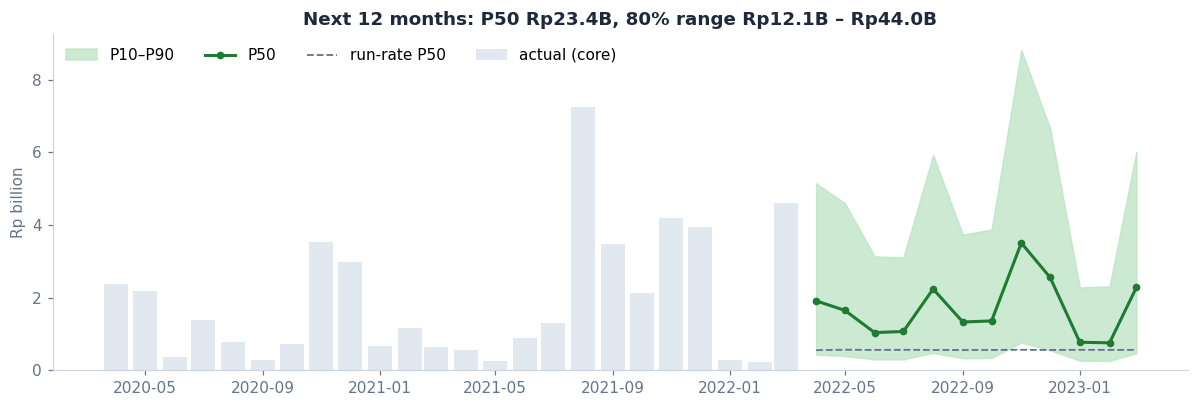

Last 12 months actual (core): Rp29.2B
Next 12 months: P10 Rp12.1B · P50 Rp23.4B · P90 Rp44.0B
  of which run-rate: P10 Rp5.8B · P50 Rp8.2B · P90 Rp11.6B


,P10,P50,P90,big-ticket share (expected)
quarter,,,,
2022Q2,Rp2.2B,Rp5.2B,Rp11.0B,65%
2022Q3,Rp2.2B,Rp5.2B,Rp10.9B,65%
2022Q4,Rp3.0B,Rp7.9B,Rp17.1B,77%
2023Q1,Rp1.8B,Rp4.4B,Rp8.9B,57%


In [8]:
last = y_all.index[-1]
fut, run, tickets = simulate(last, h=12, n=10000)
total = run + tickets
bands = pd.DataFrame(np.percentile(total, [10, 50, 90], axis=0).T, index=fut, columns=["P10", "P50", "P90"])
bands["run-rate P50"] = np.percentile(run, 50, axis=0)
bands["expected big tickets"] = tickets.mean(axis=0)
year = np.percentile(total.sum(axis=1), [10, 50, 90])
yr_run = np.percentile(run.sum(axis=1), [10, 50, 90])
last12 = y_all[-12:].sum()

fig, ax = plt.subplots(figsize=(11, 3.8))
hist = y_all["2020-04":]
ax.bar(hist.index, hist.values, width=25, color=LINE, label="actual (core)")
ax.fill_between(bands.index, bands.P10, bands.P90, color=GREEN_L, alpha=0.8, label="P10–P90")
ax.plot(bands.index, bands.P50, color=GREEN_D, lw=2, marker="o", ms=4, label="P50")
ax.plot(bands.index, bands["run-rate P50"], color=SLATE, lw=1.2, ls="--", label="run-rate P50")
ax.set_ylabel("Rp billion"); ax.legend(frameon=False, ncol=4, loc="upper left")
ax.set_title(f"Next 12 months: P50 {hd.rp(year[1] * 1e9)}, 80% range {hd.rp(year[0] * 1e9)} – {hd.rp(year[2] * 1e9)}")
plt.tight_layout(); save(fig, "forecast range"); plt.show()

print(f"Last 12 months actual (core): {hd.rp(last12 * 1e9)}")
print(f"Next 12 months: P10 {hd.rp(year[0] * 1e9)} · P50 {hd.rp(year[1] * 1e9)} · P90 {hd.rp(year[2] * 1e9)}")
print(f"  of which run-rate: P10 {hd.rp(yr_run[0] * 1e9)} · P50 {hd.rp(yr_run[1] * 1e9)} · P90 {hd.rp(yr_run[2] * 1e9)}")
quarters = pd.Index(fut.to_period("Q").astype(str))
qrows = []
for qq in quarters.unique():
    cols = np.where(quarters == qq)[0]
    qt = total[:, cols].sum(axis=1)
    qrows.append((qq, *np.percentile(qt, [10, 50, 90]), tickets[:, cols].sum(axis=1).mean() / qt.mean()))
qtab = pd.DataFrame(qrows, columns=["quarter", "P10", "P50", "P90", "big-ticket share (expected)"]).set_index("quarter")
qtab.style.format({"P10": "Rp{:.1f}B", "P50": "Rp{:.1f}B", "P90": "Rp{:.1f}B", "big-ticket share (expected)": "{:.0%}"})

**Reading the Forecast**
* **Apr 2022 – Mar 2023: P50 Rp23.4B, 80% range Rp12.1B – Rp44.0B**, against Rp29.2B in the last 12 months. The median is lower because the last 12 months were a strong budget year, and the distribution is skewed: a few extra tenders push the total towards the P90.
* **The run-rate alone is Rp8.2B (Rp5.8B – Rp11.6B).** That is the part fixed costs and staffing should be sized on.
* **Q4 2022 is the biggest quarter** (P50 Rp7.9B), and about **77%** of it is expected to come from big tickets. That is where pipeline tracking pays off most.
* Given the backtest, read P10 as a cautious floor and P90 as a *possible*, not an extreme, outcome.

## 5 · Which Customers Are Going Quiet?

Most customers buy once or twice, so "churn" here means **no order in the next six months**. A model trained on customer snapshots at the end of each quarter
from Sep 2019 to Mar 2021 (outcomes up to Sep 2021) is tested on a **later snapshot it never saw: 30 Sep 2021**, predicting who orders between Oct 2021 and Mar 2022.

Features known at the snapshot: days since the last order, orders in total and in the last 12 months, tenure, total and average spend, share of consumables,
how overdue the customer is versus their own usual gap, and segment.

  File "C:\Users\Johanna\anaconda3\lib\site-packages\joblib\externals\loky\backend\context.py", line 227, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\Johanna\anaconda3\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\Johanna\anaconda3\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Johanna\anaconda3\lib\subprocess.py", line 1420, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


Training: 4,053 customer-snapshots (23% buy). Test: 856 customers (12% buy in Oct 2021 – Mar 2022).


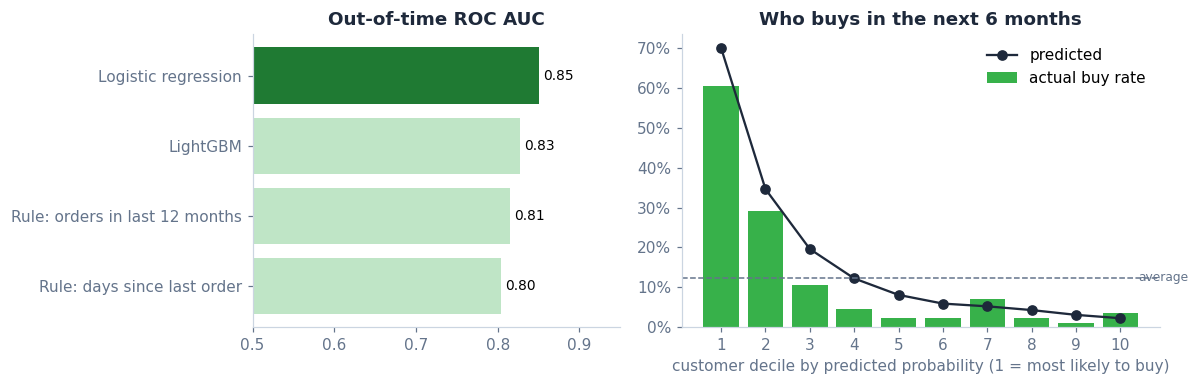

Logistic regression               0.851
LightGBM                          0.828
Rule: days since last order       0.804
Rule: orders in last 12 months    0.815
Top 20% of customers by predicted probability: buy rate 45% vs 12% average, 73% of all buyers.
Standardised coefficients (positive = more likely to order again):
log avg order                           -1.12
overdue ratio                           -0.43
log recency                             -0.31
log tenure                              -0.17
orders                                  -0.15
seg_Doctors (personal)                  -0.06
seg_Public hospitals & health offices   -0.05
seg_Companies & resellers               -0.04
seg_Private hospitals                    0.06
seg_Clinics & aesthetic chains           0.15
repeat buyer                             0.32
consumables share                        0.41
orders 12m                               0.50
log spend                                1.27


In [9]:
o2 = d.groupby(["Customer ID", "order_key"]).agg(date=("Invoice Date", "first"), amount=("Invoice Amount", "sum"), segment=("segment", "first"),
                                                 consumables=("product_group", lambda s: (s == "Consumables").mean()),
                                                 customer=("customer", "first")).reset_index()

def snapshot(t, months=6):
    t = pd.Timestamp(t)
    hist = o2[o2.date <= t]
    nxt = o2[(o2.date > t) & (o2.date <= t + pd.DateOffset(months=months))]
    g = hist.groupby("Customer ID")
    f = pd.DataFrame({"recency_days": (t - g.date.max()).dt.days, "orders": g.size(),
                      "tenure_days": (t - g.date.min()).dt.days, "spend": g.amount.sum(), "avg_order": g.amount.mean(),
                      "consumables": g.consumables.mean(), "segment": g.segment.first(), "customer": g.customer.first()})
    f["orders_12m"] = hist[hist.date > t - pd.DateOffset(months=12)].groupby("Customer ID").size().reindex(f.index).fillna(0)
    f["spend_12m"] = hist[hist.date > t - pd.DateOffset(months=12)].groupby("Customer ID").amount.sum().reindex(f.index).fillna(0)
    days = hist.drop_duplicates(["Customer ID", "date"]).sort_values("date")
    f["usual_gap"] = days.groupby("Customer ID").date.apply(lambda s: s.diff().dt.days.median()).reindex(f.index)
    f["overdue_ratio"] = (f.recency_days / f.usual_gap).fillna(f.recency_days / 365)
    f["orders_next"] = nxt.groupby("Customer ID").size().reindex(f.index).fillna(0)
    f["buys"] = (f.orders_next > 0).astype(int)
    f["snapshot"] = t
    return f

def design(f, columns=None):
    X = pd.DataFrame({"log recency": np.log1p(f.recency_days), "orders": f.orders, "orders 12m": f.orders_12m,
                      "log tenure": np.log1p(f.tenure_days), "log spend": np.log1p(f.spend), "log avg order": np.log1p(f.avg_order),
                      "consumables share": f.consumables, "repeat buyer": (f.orders > 1).astype(float), "overdue ratio": f.overdue_ratio.clip(upper=20)})
    X = pd.concat([X, pd.get_dummies(f.segment, prefix="seg").astype(float)], axis=1)
    return X.reindex(columns=columns).fillna(0) if columns is not None else X

quarter_ends = [pd.Timestamp(y, m, 1) + pd.offsets.MonthEnd(0) for y in (2019, 2020, 2021) for m in (3, 6, 9, 12)]
train_snaps = [t for t in quarter_ends if pd.Timestamp("2019-09-30") <= t <= pd.Timestamp("2021-03-31")]
train = pd.concat([snapshot(t) for t in train_snaps])
test = snapshot("2021-09-30")
Xtr = design(train); Xte = design(test, Xtr.columns)
scaler = StandardScaler().fit(Xtr)
churn_model = LogisticRegression(C=0.5, max_iter=3000).fit(scaler.transform(Xtr), train.buys)
test["p_buy"] = churn_model.predict_proba(scaler.transform(Xte))[:, 1]
gbm = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=20, verbose=-1).fit(Xtr, train.buys)

auc = pd.Series({"Logistic regression": roc_auc_score(test.buys, test.p_buy),
                 "LightGBM": roc_auc_score(test.buys, gbm.predict_proba(Xte)[:, 1]),
                 "Rule: days since last order": roc_auc_score(test.buys, -test.recency_days),
                 "Rule: orders in last 12 months": roc_auc_score(test.buys, test.orders_12m)}, name="ROC AUC (Sep 2021 snapshot)")
print(f"Training: {len(train):,} customer-snapshots ({train.buys.mean():.0%} buy). Test: {len(test):,} customers ({test.buys.mean():.0%} buy in Oct 2021 – Mar 2022).")

test["decile"] = pd.qcut(test.p_buy.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = test.groupby("decile").agg(customers=("buys", "size"), buy_rate=("buys", "mean"), predicted=("p_buy", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
a = auc.sort_values()
ax.barh(a.index, a.values, color=[GREEN_D if v == a.max() else GREEN_L for v in a.values])
for i, v in enumerate(a.values):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0.5, 0.95); ax.set_title("Out-of-time ROC AUC")
ax = axes[1]
ax.bar(lift.index.astype(int), lift.buy_rate, color=GREEN, label="actual buy rate")
ax.plot(lift.index.astype(int), lift.predicted, color=INK, marker="o", lw=1.5, label="predicted")
ax.axhline(test.buys.mean(), color=MUTED, ls="--", lw=1); ax.text(10.4, test.buys.mean(), "average", va="center", fontsize=8, color=MUTED)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xticks(range(1, 11)); ax.set_xlabel("customer decile by predicted probability (1 = most likely to buy)")
ax.legend(frameon=False); ax.set_title("Who buys in the next 6 months")
plt.tight_layout(); save(fig, "repeat purchase model"); plt.show()
print(auc.round(3).to_string())
top2 = test[test.decile.astype(int) <= 2]
print(f"Top 20% of customers by predicted probability: buy rate {top2.buys.mean():.0%} vs {test.buys.mean():.0%} average, "
      f"{top2.buys.sum() / test.buys.sum():.0%} of all buyers.")
coef = pd.Series(churn_model.coef_[0], Xtr.columns).sort_values()
print("Standardised coefficients (positive = more likely to order again):")
print(coef.round(2).to_string())

**Reading the Model**
* **Logistic regression reaches ROC AUC 0.85** on the unseen Sep 2021 snapshot, against 0.80 for "days since last order" alone and 0.82 for "orders in the last 12 months". LightGBM (0.83) is again no better than the simpler model.
* **The top 20% of customers by score hold 73% of next-period buyers**, with a 45% buy rate against a 12% average. That is a short call list instead of 856 names.
* **What raises the chance of ordering again:** many orders in the last 12 months, high total spend, and a high share of consumables (things that run out). **What lowers it:** being overdue against one's own rhythm, a long time since the last order, and a high average order (one-off device buyers). Segment adds little once behaviour is known.

### 5.1 Regular Customers Who Are Overdue

A practical list for the sales team: customers with **at least three past orders** who are now **more than twice their usual gap** since the last order.
First checked on the Sep 2021 test snapshot (did flagged customers really go quiet?), then produced for the latest data (31 Mar 2022).

In [10]:
def flag(f):
    # regular (3+ orders), still active in the last 12 months, but now more than twice their usual gap since the last order
    return (f.orders >= 3) & (f.orders_12m > 0) & (f.overdue_ratio > 2)

reg = test[(test.orders >= 3) & (test.orders_12m > 0)]
check = reg.groupby(flag(reg)).agg(customers=("buys", "size"), buy_rate=("buys", "mean"), spend_12m=("spend_12m", "sum"))
check.index = check.index.map({True: "overdue (> 2× usual gap)", False: "on schedule"})
check["spend_12m"] = check.spend_12m.map(lambda v: hd.rp(v))
print("Sep 2021 snapshot, regular customers active in the last 12 months: share that ordered in the next 6 months")
print(check.assign(buy_rate=lambda x: x.buy_rate.map("{:.0%}".format)).to_string())

now = snapshot(d["Invoice Date"].max())
Xnow = design(now, Xtr.columns)
now["p_buy"] = churn_model.predict_proba(scaler.transform(Xnow))[:, 1]
at_risk = now[flag(now)].sort_values("spend_12m", ascending=False)
active_reg = now[(now.orders >= 3) & (now.orders_12m > 0)]
print(f"\nAs of {now.snapshot.iloc[0]:%d %b %Y}: {len(active_reg)} regular customers active in the last 12 months, {len(at_risk)} of them overdue. "
      f"Their spend in the last 12 months: {hd.rp(at_risk.spend_12m.sum())} "
      f"({at_risk.spend_12m.sum() / now.spend_12m.sum():.0%} of all customers' last-12-month spend).")
show = at_risk.head(12)[["customer", "segment", "orders", "usual_gap", "recency_days", "spend_12m", "p_buy"]].copy()
show["spend_12m"] = show.spend_12m / 1e6
show.columns = ["customer", "segment", "orders", "usual gap (days)", "days since last order", "spend last 12m (Rp M)", "P(order in next 6m)"]
show.style.hide(axis="index").format({"usual gap (days)": "{:.0f}", "spend last 12m (Rp M)": "{:,.0f}", "P(order in next 6m)": "{:.0%}"})

Sep 2021 snapshot, regular customers active in the last 12 months: share that ordered in the next 6 months
                          customers buy_rate spend_12m
on schedule                     102      56%    Rp5.1B
overdue (> 2× usual gap)         80      19%    Rp2.9B

As of 30 Mar 2022: 149 regular customers active in the last 12 months, 59 of them overdue. Their spend in the last 12 months: Rp0.7B (2% of all customers' last-12-month spend).


customer,segment,orders,usual gap (days),days since last order,spend last 12m (Rp M),P(order in next 6m)
Clinic 005,Clinics & aesthetic chains,21,20,49,289,87%
Clinic 006,Clinics & aesthetic chains,19,22,142,92,79%
Clinic 020,Clinics & aesthetic chains,13,27,133,62,78%
Company 026,Companies & resellers,6,28,138,31,24%
Clinic 024,Clinics & aesthetic chains,13,44,317,29,40%
Doctor 008,Doctors (personal),11,25,236,29,26%
Clinic 025,Clinics & aesthetic chains,21,34,145,27,83%
Doctor 020,Doctors (personal),71,11,70,22,88%
Doctor 033,Doctors (personal),22,33,111,15,48%
Doctor 067,Doctors (personal),13,70,155,10,42%


**Reading the List**
* **The overdue flag works.** In the Sep 2021 test, regular customers more than twice past their usual gap ordered again only **19%** of the time, against **56%** for those on schedule.
* **Today 59 of 149 active regular customers are overdue.** Together they spent **Rp0.7B** in the last 12 months. That is small next to the big tickets, but it is repeat revenue at near-zero acquisition cost, and mostly **clinics and doctors buying consumables**.
* Customers still scoring high (e.g. *Clinic 005*: usually every 20 days, now 49 days quiet, 87% likely to return) need only a reminder. Customers scoring low (e.g. *Company 026*, *Doctor 008*) need a sales visit or a reason why they stopped.

## 6 · What This Adds to the Dashboard

| Dashboard says | Notebook adds |
|---|---|
| A few large public orders make up most of the revenue | **Public buyers: 7% of customers, 57% of revenue, 90% of it in big tickets.** Clinics are the loyal base (9 orders per customer). |
| Revenue peaks at year-end | A measurable **budget calendar**: public buyers spend 0% in Jan–Feb and 59% in Aug, Nov and Dec. |
| Monthly revenue is volatile | **Why it cannot be forecast from history** (60% error at best, all methods biased low), and that the **run-rate can** (33–34%). |
| — | A **forecast range** for the next 12 months (P50 Rp23.4B, Rp12.1B – Rp44.0B), with its own honesty check. |
| — | A **repeat-purchase model** (AUC 0.85 out of time) and a list of **59 overdue regular customers**. |

**Recommendations**
1. **Plan on the run-rate, manage the big tickets.** Size costs and stock on the run-rate (Rp8B a year) and treat tenders as a pipeline: expected value × probability × month.
2. **Build a tender pipeline sheet** (customer, item, value, expected month, stage). Feeding it into the simulation in place of the historical ticket rate turns the widest part of the range into known numbers.
3. **Follow the budget calendar.** Prepare quotes and stock in Q2–Q3 for August and November–December. Use the quiet January–February for clinics and doctors.
4. **Run a monthly "overdue regulars" call list** from the repeat-purchase model, starting with high-value customers whose score is falling.
5. **Add the forecast and the at-risk flag to Power BI** as tables, so the dashboard shows next quarter's range and who to call, not only last quarter's sales.

### Limitations
* Three years of history is short for yearly seasonality: each calendar month has only three observations, and 2020–21 were distorted by COVID budget reallocation.
* Big tickets are mostly public tenders. Their timing depends on tender calendars and approvals that are not in this data, so a **sales pipeline** (expected tender, value, probability) would beat any time-series model here.
* Segments come from customer names (keyword rules). A customer master with a proper type field would be more accurate.
* "Churn" for a distributor of durable devices is ambiguous: a hospital that bought a laser may not need another for years. The repeat-purchase model is most useful for consumables buyers and clinics.